# Pronóstico horario de demanda de taxis

**Autor:** Luis Eduardo Aguilar Castellanos · Data Science en TripleTen.

Desarrollé un pronóstico a una hora para Sweet Lift Taxi con el objetivo de apoyar la planificación de conductores en aeropuertos. Comparé modelos de regresión con validación temporal y reservé el 10 % final de la serie para evaluar la configuración elegida.

El criterio del ejercicio es obtener RMSE ≤ 48 pedidos en prueba. Para interpretar ese resultado, comparé el modelo con dos referencias: la demanda de la hora anterior y la de la misma hora del día anterior.

La evaluación avanza hora a hora: para predecir cada hora utilizo observaciones reales disponibles hasta la hora previa. No es un pronóstico de varias jornadas realizado desde un único punto de origen.

## Recorrido

1. Calidad y agregación horaria de los datos.
2. Exploración del tramo de entrenamiento.
3. Características temporales y validación cronológica.
4. Comparación y selección de modelos.
5. Evaluación final y análisis de errores.

Consulta el README para instalar las dependencias y configurar `TAXI_DATA_PATH`. Los datos originales no se incluyen en el repositorio.


## 1. Preparación de los datos

In [1]:
import os
from pathlib import Path
from IPython.display import display
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import TimeSeriesSplit, train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import lightgbm as lgb

%matplotlib inline

data_path = Path(os.environ.get("TAXI_DATA_PATH", "data/raw/taxi.csv"))
if not data_path.is_file():
    raise FileNotFoundError("Configura TAXI_DATA_PATH o coloca taxi.csv en data/raw/. Consulta data/README.md.")
df = pd.read_csv(data_path, index_col=0, parse_dates=[0])
assert list(df.columns) == ["num_orders"], "Se esperaba la columna num_orders."
assert isinstance(df.index, pd.DatetimeIndex), "El índice debe ser temporal."
assert df.index.is_monotonic_increasing and df.index.is_unique, "Revisar orden o duplicados temporales."
assert not df.isna().any().any(), "Hay valores ausentes."
assert df["num_orders"].ge(0).all(), "Hay cantidades negativas."
expected_index = pd.date_range(df.index.min(), df.index.max(), freq="10min")
assert df.index.equals(expected_index), "La serie no contiene todos los intervalos de 10 minutos."
print("Registros originales:", len(df))
display(df.describe().round(2))


Matplotlib is building the font cache; this may take a moment.


Registros originales: 26496


,num_orders
count,26496.00
mean,14.07
std,9.21
min,0.00
25%,8.00
50%,13.00
75%,19.00
max,119.00


### Agregación y división temporal

Sumé los pedidos de cada hora y comprobé que la serie mantuviera intervalos regulares. Separé entrenamiento y prueba antes de explorar patrones para orientar el modelo. El tramo de prueba conserva el 10 % final de las horas, sin mezclar registros.


In [2]:
df = df.resample("1h").sum().asfreq("1h")
assert not df.isna().any().any()
train_data, test_data = train_test_split(df, shuffle=False, test_size=0.10)
assert train_data.index.max() < test_data.index.min()
display(pd.DataFrame([
    {"conjunto":"Entrenamiento", "horas":len(train_data), "inicio":train_data.index.min(), "fin":train_data.index.max()},
    {"conjunto":"Prueba", "horas":len(test_data), "inicio":test_data.index.min(), "fin":test_data.index.max()},
]))


,conjunto,horas,inicio,fin
0,Entrenamiento,3974,2018-03-01 00:00:00,2018-08-13 13:00:00
1,Prueba,442,2018-08-13 14:00:00,2018-08-31 23:00:00


## 2. Exploración de la demanda

Analicé tendencia y patrones diarios sobre entrenamiento. La media móvil de 24 horas ayuda a observar el nivel general; la descomposición con período 24 describe el ciclo diario. Estas visualizaciones no demuestran por sí solas estacionariedad ni explican las causas de los cambios.


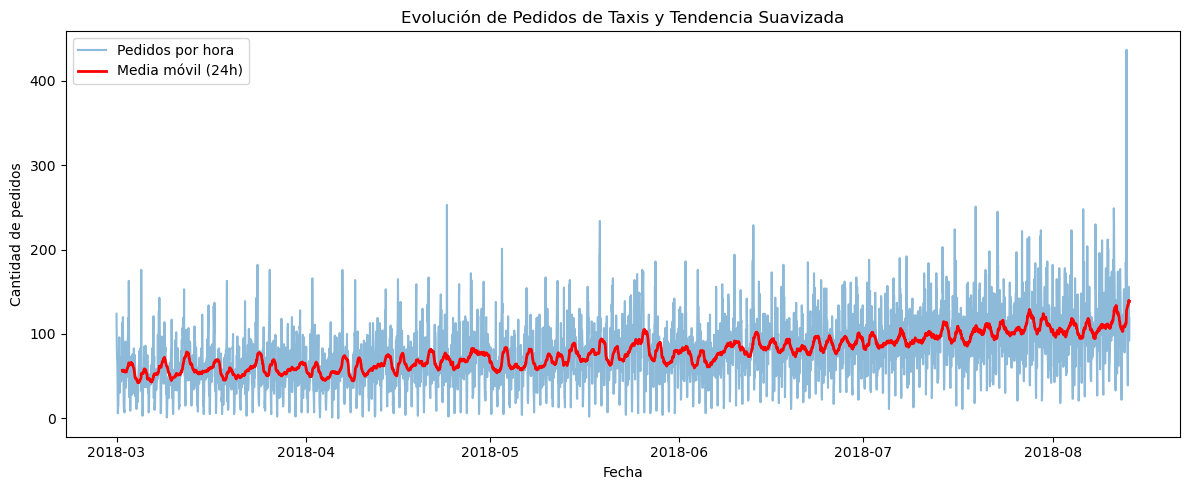

In [3]:
# Calculamos una media móvil de 24 horas para suavizar el ruido diario
rolling_mean = train_data["num_orders"].rolling(24).mean()

plt.figure(figsize=(12, 5))
plt.plot(train_data.index, train_data["num_orders"], label="Pedidos por hora", alpha=0.5)
plt.plot(
    train_data.index, rolling_mean, label="Media móvil (24h)", color="red", linewidth=2
)
plt.title("Evolución de Pedidos de Taxis y Tendencia Suavizada")
plt.xlabel("Fecha")
plt.ylabel("Cantidad de pedidos")
plt.legend()
plt.tight_layout()
plt.show()

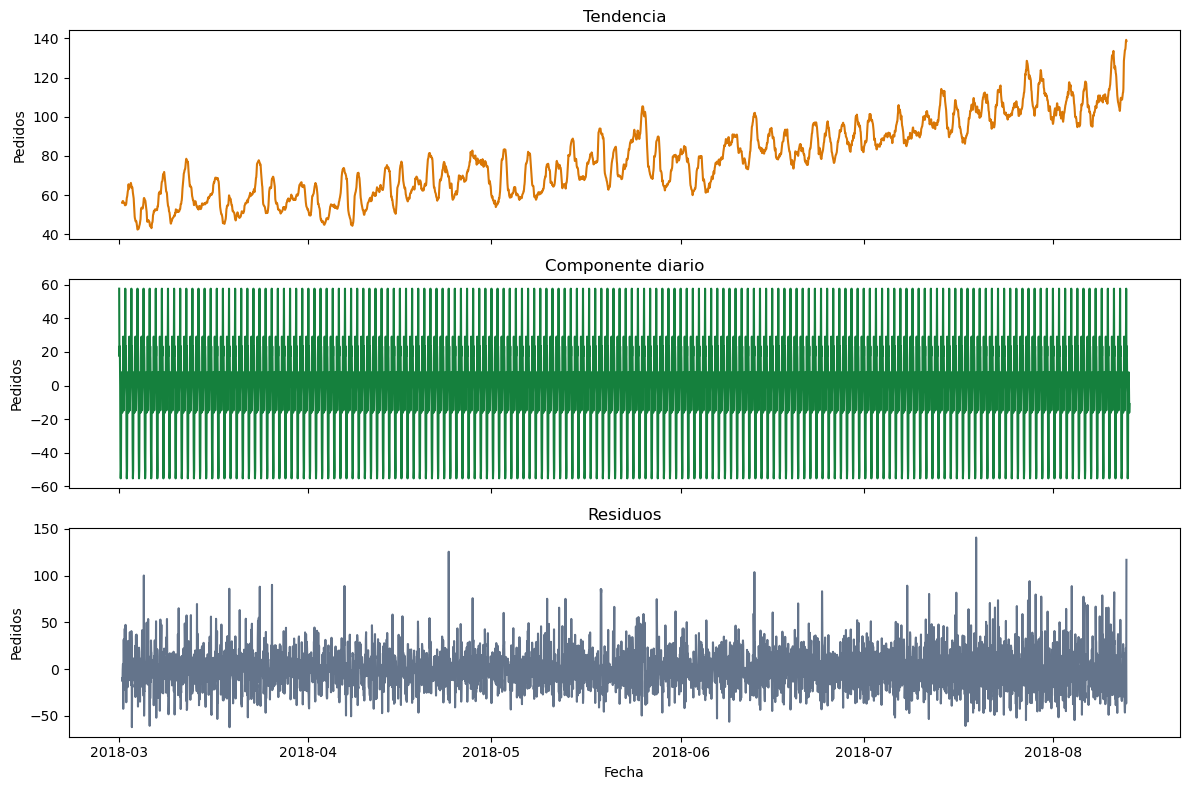

In [4]:
decomposed = seasonal_decompose(train_data["num_orders"], period=24)
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, values, title, color in zip(
    axes, [decomposed.trend, decomposed.seasonal, decomposed.resid],
    ["Tendencia", "Componente diario", "Residuos"], ["#d97706", "#15803d", "#64748b"]
):
    ax.plot(values.index, values, color=color)
    ax.set_title(title)
    ax.set_ylabel("Pedidos")
axes[-1].set_xlabel("Fecha")
plt.tight_layout()
plt.show()


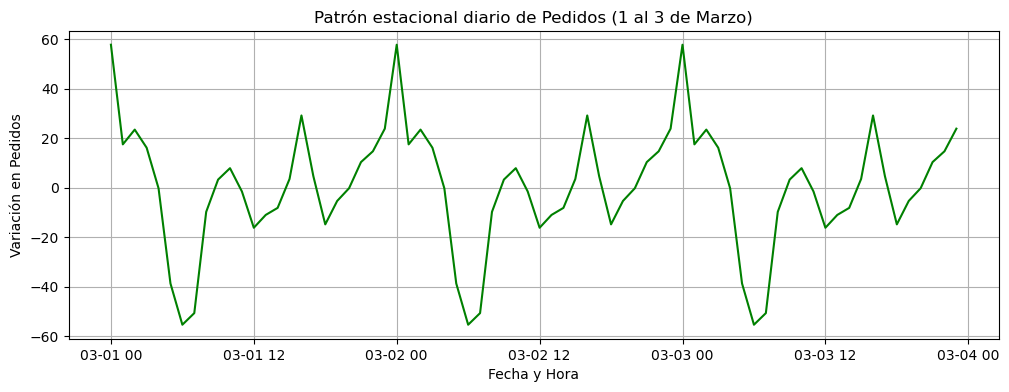

In [5]:
plt.figure(figsize=(12, 4))
plt.plot(decomposed.seasonal['2018-03-01':'2018-03-03'], color='green')
plt.title('Patrón estacional diario de Pedidos (1 al 3 de Marzo)')
plt.xlabel('Fecha y Hora')
plt.ylabel('Variación en Pedidos')
plt.grid(True)
plt.show()

Observé un aumento del nivel de demanda y un patrón diario marcado. Por ello incluí hora, día de la semana, pedidos previos y una media móvil como características. La tendencia y los cambios de demanda hacen necesario comprobar el rendimiento en períodos posteriores.

## 3. Características temporales y validación

Creé retardos y calculé la media móvil después de aplicar `shift(1)`, para excluir la demanda de la hora que intento predecir. Para comparar configuraciones utilicé tres divisiones de `TimeSeriesSplit`: en cada una, el entrenamiento precede a la validación.


In [6]:
def make_features(data, max_lag, rolling_mean_size):
  df_feat = data.copy()

  # Características de calendario
  df_feat['hour'] = df_feat.index.hour
  df_feat['dayofweek'] = df_feat.index.dayofweek

  # Lags (Valores previos)
  for lag in range(1, max_lag + 1):
    df_feat[f'lag_{lag}'] = df_feat['num_orders'].shift(lag)

  # Media móvil (usamos shift(1) para evitar la filtración de datos del presente/futuro)
  df_feat['rolling_mean'] = (
      df_feat['num_orders'].shift(1).rolling(rolling_mean_size).mean()
  )

  return df_feat




### Búsqueda de características

Comparé 12 combinaciones: 1, 6, 12 o 24 retardos y ventanas de 6, 12 o 24 horas. Utilicé regresión lineal para elegir la combinación con menor RMSE promedio de validación. Conservé el mismo inicio del tramo final de prueba al eliminar las filas sin historial suficiente.


In [7]:
best_rmse = float('inf')
best_lag = None
best_roll = None
feature_results = []

# Definimos candidatos a probar (por ejemplo, lapsos de 1 a 24 horas y ventanas de 6 a 24 horas)
lags_to_test = [1, 6, 12, 24]
rolls_to_test = [6, 12, 24]

# Usamos TimeSeriesSplit para no violar el orden temporal en la validación
tscv = TimeSeriesSplit(n_splits=3)

for lag in lags_to_test:
  for roll in rolls_to_test:
    df_temp = make_features(df, lag, roll).dropna()

    # Al crear lags y media móvil se eliminan filas iniciales por falta de historial.
    # La cantidad eliminada corresponde al mayor valor entre lag y ventana móvil,
    # no a la suma de ambos.
    rows_removed_temp = max(lag, roll)

    # Usamos únicamente el 90% inicial reservado para entrenamiento.
    # El 10% final permanece intacto para la prueba final.
    X_tr = df_temp.drop("num_orders", axis=1).iloc[
    : len(train_data) - rows_removed_temp
    ]
    y_tr = df_temp["num_orders"].iloc[
    : len(train_data) - rows_removed_temp
    ]

    model_temp = LinearRegression()

    # Evaluamos con TimeSeriesSplit usando RECM (neg_mean_squared_error)
    scores = cross_val_score(
        model_temp,
        X_tr,
        y_tr,
        cv=tscv,
        scoring='neg_mean_squared_error',
    )
    rmse_cv = np.mean(np.sqrt(-scores))

    feature_results.append({"max_lag":lag, "rolling_window":roll, "rmse_cv":float(rmse_cv)})

    if rmse_cv < best_rmse:
      best_rmse = rmse_cv
      best_lag = lag
      best_roll = roll

print(
    f'Mejor combinación encontrada -> max_lag: {best_lag},'
    f' rolling_mean_size: {best_roll} con RECM de CV: {best_rmse:.2f}'
)

# Preparamos los datos finales usando los mejores parámetros encontrados
df_prepared = make_features(
    df,
    max_lag=best_lag,
    rolling_mean_size=best_roll
).dropna()

# make_features elimina filas iniciales porque no existen suficientes
# valores previos para crear lags y la media móvil.
# La cantidad real de filas eliminadas es el mayor de ambos valores,
# NO la suma de lag + ventana móvil.
rows_removed = max(best_lag, best_roll)

# train_data ya conserva el 90% inicial de la serie original.
# Ajustamos el índice solo por las filas iniciales eliminadas al hacer dropna().
split_index = len(train_data) - rows_removed

# Con este corte, el test conserva exactamente el 10% final original:
# 442 filas de 4,416 observaciones horarias.
X = df_prepared.drop("num_orders", axis=1)
y = df_prepared["num_orders"]

X_train = X.iloc[:split_index]
y_train = y.iloc[:split_index]

X_test = X.iloc[split_index:]
y_test = y.iloc[split_index:]

print(f"Tamaño final de Train: {X_train.shape[0]}")
print(f"Tamaño final de Test: {X_test.shape[0]}")
print(f"Inicio del conjunto de prueba: {X_test.index.min()}")
assert X_train.index.max() < X_test.index.min()
assert X_test.index.equals(test_data.index), "El corte temporal de prueba cambió."
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
for train_idx, valid_idx in tscv.split(X_train):
    assert X_train.index[train_idx].max() < X_train.index[valid_idx].min()
display(pd.DataFrame(feature_results).sort_values("rmse_cv").round(3))


Mejor combinación encontrada -> max_lag: 24, rolling_mean_size: 6 con RECM de CV: 27.77
Tamaño final de Train: 3950
Tamaño final de Test: 442
Inicio del conjunto de prueba: 2018-08-13 14:00:00


,max_lag,rolling_window,rmse_cv
9,24,6,27.773
10,24,12,27.773
11,24,24,27.773
8,12,24,32.486
5,6,24,32.708
2,1,24,32.764
6,12,6,33.227
7,12,12,33.227
4,6,12,33.458
1,1,12,33.547


### Comparación de modelos

Evalué regresión lineal, bosque aleatorio y LightGBM con las mismas características y divisiones temporales. Probé nueve configuraciones para cada ensamble. Seleccioné por el promedio de los RMSE de los folds; este valor no es el RMSE combinado de todas las observaciones.


In [8]:
# ---------------------------------------------------------
# 1. Regresión Lineal (Sin hiperparámetros complejos)
# ---------------------------------------------------------
model_lr = LinearRegression()
scores_lr = cross_val_score(
    model_lr, X_train, y_train, cv=tscv, scoring='neg_mean_squared_error'
)
rmse_lr_cv = np.mean(np.sqrt(-scores_lr))
model_lr.fit(X_train, y_train)

print(f'RECM CV - Regresión Lineal: {rmse_lr_cv:.2f}\n')

# ---------------------------------------------------------
# 2. Random Forest Regressor (Búsqueda de hiperparámetros)
# ---------------------------------------------------------
best_rf_rmse = float('inf')
best_rf_depth = None
best_rf_estimators = None

# Definimos las opciones a probar para la profundidad y número de árboles
param_depths_rf = [8, 12, 16]
param_estimators_rf = [50, 100, 150]

# Recorremos cada combinación de hiperparámetros
for depth in param_depths_rf:
    for n_est in param_estimators_rf:
        rf_temp = RandomForestRegressor(
            n_estimators=n_est, max_depth=depth, random_state=42, n_jobs=1
        )
        scores = cross_val_score(
            rf_temp,
            X_train,
            y_train,
            cv=tscv,
            scoring='neg_mean_squared_error',
        )
        rmse = np.mean(np.sqrt(-scores))

        # Si encontramos un error menor, actualizamos la mejor combinación
        if rmse < best_rf_rmse:
            best_rf_rmse = rmse
            best_rf_depth = depth
            best_rf_estimators = n_est

# Entrenamos el modelo final de Random Forest con la mejor combinación encontrada
model_rf = RandomForestRegressor(
    n_estimators=best_rf_estimators, max_depth=best_rf_depth, random_state=42, n_jobs=1
)
model_rf.fit(X_train, y_train)
rmse_rf_cv = best_rf_rmse

print(
    f'Mejor Random Forest -> max_depth: {best_rf_depth}, n_estimators: {best_rf_estimators}'
)
print(f'RECM CV - Random Forest: {rmse_rf_cv:.2f}\n')

# ---------------------------------------------------------
# 3. LightGBM Regressor (Búsqueda de hiperparámetros)
# ---------------------------------------------------------
best_lgb_rmse = float('inf')
best_lgb_lr = None
best_lgb_estimators = None

# Definimos las opciones de tasa de aprendizaje y número de árboles
param_learning_rates = [0.03, 0.05, 0.1]
param_estimators_lgb = [50, 100, 150]

# Recorremos cada combinación
for lr in param_learning_rates:
    for n_est in param_estimators_lgb:
        lgb_temp = lgb.LGBMRegressor(
            n_estimators=n_est, learning_rate=lr, max_depth=8, random_state=42, n_jobs=1, verbose=-1
        )
        scores = cross_val_score(
            lgb_temp,
            X_train,
            y_train,
            cv=tscv,
            scoring='neg_mean_squared_error',
        )
        rmse = np.mean(np.sqrt(-scores))

        # Si encontramos un error menor, guardamos los valores
        if rmse < best_lgb_rmse:
            best_lgb_rmse = rmse
            best_lgb_lr = lr
            best_lgb_estimators = n_est

# Entrenamos el modelo final de LightGBM con la mejor combinación encontrada
model_lgb = lgb.LGBMRegressor(
    verbose=-1,
    n_jobs=1,
    n_estimators=best_lgb_estimators,
    learning_rate=best_lgb_lr,
    max_depth=8,
    random_state=42
)
model_lgb.fit(X_train, y_train)
rmse_lgb_cv = best_lgb_rmse

print(
    f'Mejor LightGBM -> learning_rate: {best_lgb_lr}, n_estimators: {best_lgb_estimators}'
)
print(f'RECM CV - LightGBM: {rmse_lgb_cv:.2f}')

RECM CV - Regresión Lineal: 27.77



Mejor Random Forest -> max_depth: 16, n_estimators: 50
RECM CV - Random Forest: 26.84



Mejor LightGBM -> learning_rate: 0.03, n_estimators: 150
RECM CV - LightGBM: 26.51


### Referencias sobre las mismas divisiones

Calculé dos pronósticos simples sin entrenar parámetros: repetir la hora anterior y repetir la misma hora del día anterior. Los evalué sobre las mismas fechas de validación que los modelos, para comparar errores equivalentes.


In [9]:
baseline_predictions = {
    "Hora anterior": df["num_orders"].shift(1),
    "Misma hora del día anterior": df["num_orders"].shift(24),
}
baseline_cv = {}
for name, prediction in baseline_predictions.items():
    fold_rmse = []
    for _, valid_idx in tscv.split(X_train):
        valid_dates = X_train.index[valid_idx]
        values = prediction.reindex(valid_dates)
        assert values.notna().all()
        fold_rmse.append(float(np.sqrt(mean_squared_error(y_train.loc[valid_dates], values))))
    baseline_cv[name] = float(np.mean(fold_rmse))

model_cv = {"Regresión lineal":float(rmse_lr_cv), "Bosque aleatorio":float(rmse_rf_cv), "LightGBM":float(rmse_lgb_cv)}
model_candidates = {"Regresión lineal":model_lr, "Bosque aleatorio":model_rf, "LightGBM":model_lgb}
selected_name = min(model_cv, key=model_cv.get)
selected_model = model_candidates[selected_name]
comparison = pd.DataFrame([
    {"modelo":name, "rmse_cv":score, "tipo":"Modelo entrenado"} for name, score in model_cv.items()
] + [
    {"modelo":name, "rmse_cv":score, "tipo":"Referencia temporal"} for name, score in baseline_cv.items()
]).sort_values("rmse_cv").reset_index(drop=True)
display(comparison.round(3))
print("Modelo seleccionado en validación:", selected_name)


,modelo,rmse_cv,tipo
0,LightGBM,26.513,Modelo entrenado
1,Bosque aleatorio,26.837,Modelo entrenado
2,Regresión lineal,27.773,Modelo entrenado
3,Misma hora del día anterior,33.199,Referencia temporal
4,Hora anterior,37.985,Referencia temporal


Modelo seleccionado en validación: LightGBM


## 4. Evaluación final

Evalué el modelo seleccionado sobre el 10 % final de la serie y comparé las dos referencias en esas mismas horas. Para cada pronóstico a una hora se dispone del historial real hasta la hora anterior, también dentro del período de prueba. Esta evaluación no representa generar todas las predicciones futuras sin recibir nuevas observaciones.

El tramo de prueba corresponde al utilizado en el análisis inicial; repetir su evaluación no aporta una nueva validación independiente.


In [10]:
predictions_test = selected_model.predict(X_test)
rmse_final = float(np.sqrt(mean_squared_error(y_test, predictions_test)))
baseline_test = {}
for name, prediction in baseline_predictions.items():
    values = prediction.reindex(y_test.index)
    assert values.notna().all()
    baseline_test[name] = float(np.sqrt(mean_squared_error(y_test, values)))
test_comparison = pd.DataFrame([
    {"modelo":selected_name, "rmse_test":rmse_final}
] + [{"modelo":name,"rmse_test":score} for name,score in baseline_test.items()])
display(test_comparison.round(3))
print("Cumple RMSE ≤ 48:", rmse_final <= 48)


,modelo,rmse_test
0,LightGBM,41.124
1,Hora anterior,58.856
2,Misma hora del día anterior,57.187


Cumple RMSE ≤ 48: True


### Predicciones y errores

Comparé las primeras siete jornadas de prueba para observar picos y valles. También revisé la distribución del error en todas las horas de prueba. Un RMSE global puede ocultar subestimaciones en horas de demanda alta.


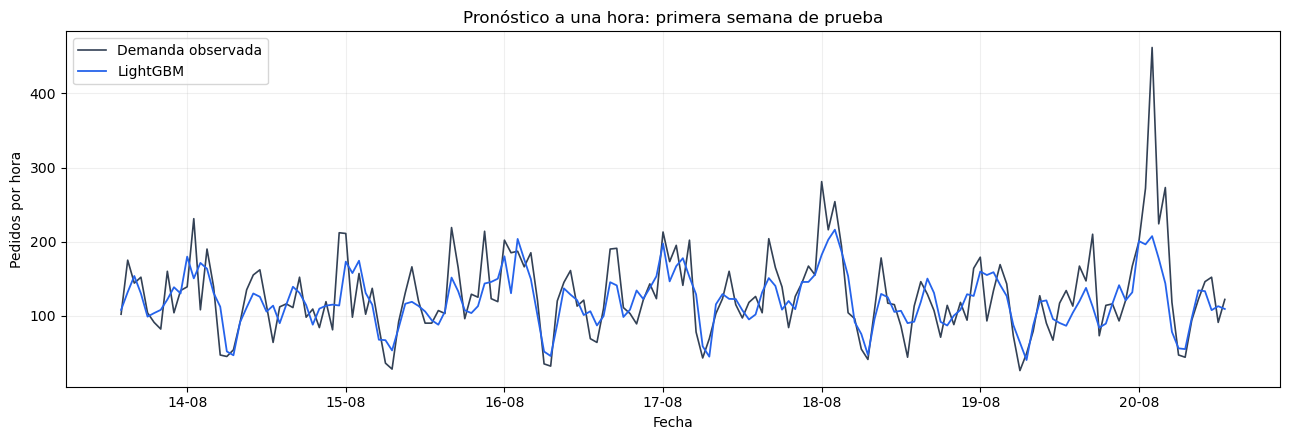

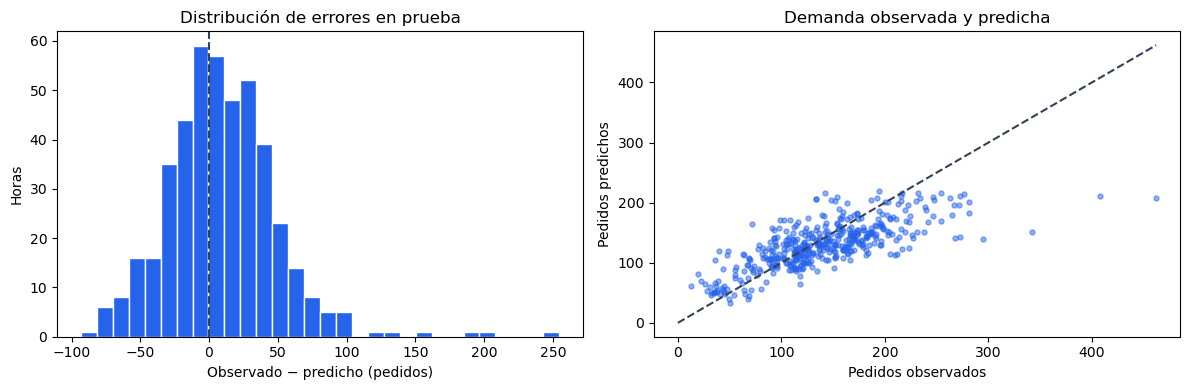

In [11]:
Path("assets").mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(13, 4.5))
window = min(168, len(y_test))
dates = y_test.index[:window]
ax.plot(dates, y_test.iloc[:window], label="Demanda observada", color="#334155", linewidth=1.2)
ax.plot(dates, predictions_test[:window], label=selected_name, color="#2563eb", linewidth=1.3)
ax.set_title("Pronóstico a una hora: primera semana de prueba")
ax.set_xlabel("Fecha")
ax.set_ylabel("Pedidos por hora")
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%m"))
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig("assets/pronostico_horario.png", dpi=150, bbox_inches="tight")
plt.show()

residuals = y_test.to_numpy() - predictions_test
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(residuals, bins=30, color="#2563eb", edgecolor="white")
axes[0].axvline(0, color="#334155", linestyle="--")
axes[0].set_title("Distribución de errores en prueba")
axes[0].set_xlabel("Observado − predicho (pedidos)")
axes[0].set_ylabel("Horas")
axes[1].scatter(y_test, predictions_test, s=13, alpha=0.5, color="#2563eb")
limit = max(float(y_test.max()), float(np.max(predictions_test)))
axes[1].plot([0,limit], [0,limit], "--", color="#334155")
axes[1].set_title("Demanda observada y predicha")
axes[1].set_xlabel("Pedidos observados")
axes[1].set_ylabel("Pedidos predichos")
fig.tight_layout()
fig.savefig("assets/errores_prueba.png", dpi=150, bbox_inches="tight")
plt.show()


## 5. Resultados y conclusiones

El resumen siguiente presenta el error del modelo y de las referencias sobre las mismas horas de prueba. La reducción relativa de RMSE describe error predictivo, no una reducción de costos operativos.


In [12]:
from datetime import datetime, timezone
from importlib.metadata import version
import platform
import json

metrics = {
    "executed_at_utc":datetime.now(timezone.utc).isoformat(),
    "python":platform.python_version(), "platform":platform.system(),
    "model":selected_name, "rmse_cv":model_cv[selected_name], "rmse_test":rmse_final,
    "target_rmse_max":48, "target_met":bool(rmse_final<=48),
    "n_hours":len(df), "n_train_raw":len(train_data), "n_train_features":len(X_train), "n_test":len(X_test),
    "test_start":str(y_test.index.min()), "test_end":str(y_test.index.max()),
    "max_lag":int(best_lag), "rolling_window":int(best_roll),
    "cv_splits":3, "seed":42, "forecast_horizon_hours":1,
    "evaluation":"Origen móvil a un paso, con observaciones reales previas; tramo histórico de prueba",
    "baseline_rmse_test":baseline_test,
    "relative_rmse_reduction_vs_previous_hour":float(1-rmse_final/baseline_test["Hora anterior"]),
    "mean_error_observed_minus_predicted":float(np.mean(residuals)),
    "model_params":selected_model.get_params(),
    "versions":{p:version(p) for p in ["numpy","pandas","scipy","scikit-learn","lightgbm","statsmodels","matplotlib"]},
}
Path("reports").mkdir(exist_ok=True)
Path("reports/metrics.json").write_text(json.dumps(metrics,ensure_ascii=False,indent=2)+"\n",encoding="utf-8")
comparison.to_csv("reports/model_comparison.csv",index=False)
test_comparison.to_csv("reports/test_comparison.csv",index=False)
pd.DataFrame(feature_results).to_csv("reports/feature_comparison.csv",index=False)
display(pd.DataFrame([{
    "Modelo":selected_name,"RMSE CV":model_cv[selected_name],"RMSE prueba":rmse_final,
    "RMSE hora anterior":baseline_test["Hora anterior"],
    "RMSE día anterior":baseline_test["Misma hora del día anterior"],
    "Horas de prueba":len(y_test),
}]).round(3))


,Modelo,RMSE CV,RMSE prueba,RMSE hora anterior,RMSE día anterior,Horas de prueba
0,LightGBM,26.513,41.124,58.856,57.187,442


### Alcance y siguientes pasos

Utilicé el orden temporal para entrenar con el pasado y validar en intervalos posteriores. Los retardos y la media móvil incorporan solamente información previa a cada hora predicha.

La selección de características y parámetros reutiliza los folds de desarrollo, por lo que el error de validación puede ser optimista. El tramo de prueba histórico permite contrastar el resultado, pero necesito más períodos para evaluar su estabilidad.

La demanda puede cambiar por eventos, clima, disponibilidad de transporte o estacionalidad no representada en la muestra. El análisis de tendencia es descriptivo y no demuestra causalidad. Antes de usar el pronóstico para asignar conductores, compararía su efecto sobre disponibilidad, tiempos de espera y costos.
